In [1]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [2]:
df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df['smoker'] = df['smoker'].map({'yes':1, 'no':0})

In [4]:

class_counts = df["smoker"].value_counts(normalize=True) * 100
print(f'Баланс классов:\n0 (Не курит): {class_counts[0]:.1f}%\n1 (Курит): {class_counts[1]:.1f}%')

X= df.drop("smoker", axis=1)
y = df["smoker"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(df.columns)

Баланс классов:
0 (Не курит): 79.5%
1 (Курит): 20.5%
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')


Определили процент курящих и не курящих.

In [ ]:
numeric_features = ['age', 'bmi', 
       'children', 'charges']
categorical_features = ['sex',
       'region']
numeric_transformer= Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)
categorical_transformer= Pipeline(
    steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

clf_pipeline = Pipeline(
    steps=[("preprocessor", preprocessor), ("classifier", KNeighborsClassifier())]
)

param_grid = {
    "classifier__n_neighbors": [3,5,9],
    "classifier__weights": ["uniform","distance"],
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=clf_pipeline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_model=grid_search.best_estimator_
print(f'\nЛучшие параметры алгоритма:{grid_search.best_params_}')


Лучшие параметры алгоритма:{'classifier__n_neighbors': 9, 'classifier__weights': 'distance'}


Вывели лучшие параметры алгоритма

In [13]:
y_pred = best_model.predict(X_test)

y_proba = best_model.predict_proba(X_test)[:, 1]

print("Матрица ошибок")
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Истинно отрицательные (TN - не курящий, определили) {conf_matrix[0][0]}")
print(f"Ложноположительные (FP - курящий, не определили) {conf_matrix[0][1]}")
print(f"Ложноотрицательные  (FN- некурящий, не определили) {conf_matrix[1][0]}")
print(f"Истинно положительныен) (TP- курящий, определили {conf_matrix[1][1]}")

print("Матрица ошибок")
print(classification_report(y_test, y_pred, target_names=["Не курит (0)", "Курит (1)"]))

roc_auc = roc_auc_score(y_test, y_proba)
print(f"Площадь под кривой ROC-AUC: {roc_auc:.4f}")

Матрица ошибок
Истинно отрицательные (TN - не курящий, определили) 211
Ложноположительные (FP - курящий, не определили) 2
Ложноотрицательные  (FN- некурящий, не определили) 12
Истинно положительныен) (TP- курящий, определили 43
Матрица ошибок
              precision    recall  f1-score   support

Не курит (0)       0.95      0.99      0.97       213
   Курит (1)       0.96      0.78      0.86        55

    accuracy                           0.95       268
   macro avg       0.95      0.89      0.91       268
weighted avg       0.95      0.95      0.95       268

Площадь под кривой ROC-AUC: 0.9704


In [7]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [8]:
df_reg = df.dropna(subset=['age', 'bmi', 
       'children']).copy()
X_reg = df_reg[['age', 'bmi', 
       'children']]
y_reg = df_reg["charges"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

reg_pipeline = Pipeline([
    ("scaler", StandardScaler()), ("knn_reg", KNeighborsRegressor())
])

kf = KFold(n_splits=5, shuffle=True, random_state=42)
param_dist = {
    "knn_reg__n_neighbors": np.arange(3, 30),
    "knn_reg__weights": ["uniform", "distance"],
}

random_search = RandomizedSearchCV(
    estimator=reg_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    cv=kf,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_r, y_train_r)
best_reg = random_search.best_estimator_
print(f"\nЛучшие параметры алгоритма: {random_search.best_params_}")



Лучшие параметры алгоритма: {'knn_reg__weights': 'uniform', 'knn_reg__n_neighbors': np.int64(27)}


Вывели лучший параметр алгоритма

In [9]:
y_pred_r = best_reg.predict(X_test_r)

def smape(y_test, y_pred):
    return 100 * np.mean(
        2 * np.abs(y_pred - y_test) / (np.abs(y_test) + np.abs(y_pred))
    )
mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_r, y_pred_r)
smape_value = smape(y_test_r, y_pred_r)

print("--- Отчет по метрикам регрессии ---")
print(f"MSE (квадратные \$) {mse:,.0f}")
print(f"RMSE (\$) {rmse:,.2f}")
print(f"MAE (Средняя ошибка) {mae:,.2f}")
print(f"SMAPE (Ошибка в % \$) {smape_value:,.2f}")

--- Отчет по метрикам регрессии ---
MSE (квадратные \$) 135,085,905
RMSE (\$) 11,622.65
MAE (Средняя ошибка) 9,114.98
SMAPE (Ошибка в % \$) 72.60


Показатель SMAPE в 72.6% - терпимый результат, учитывая, что максимумальный показатель % - 200,ошибки только в 36%.


Text(0, 0.5, 'Кол-во клиентов')

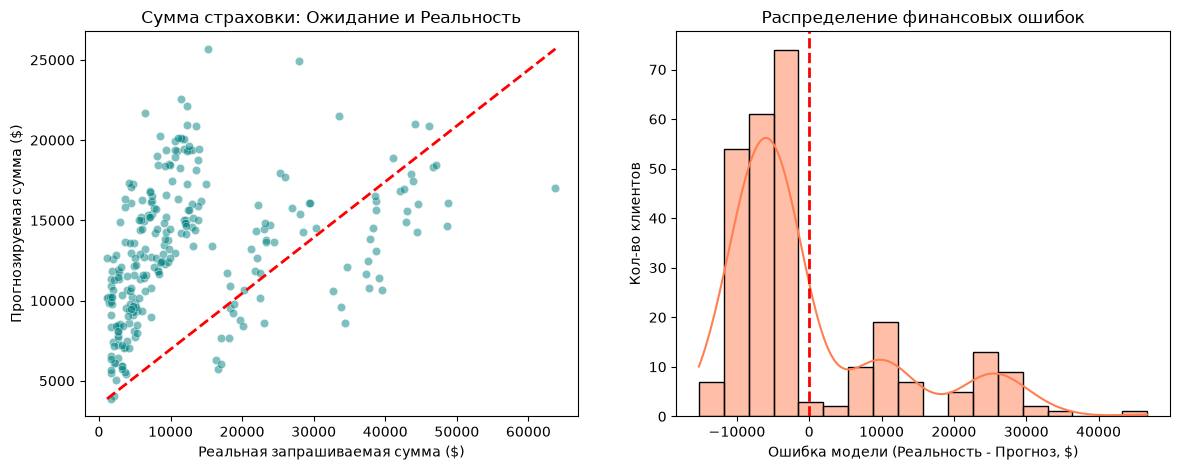

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2,figsize=(14,5))

sns.scatterplot(x=y_test_r, y=y_pred_r, alpha=0.5, color= 'teal', ax=axes[0])
axes[0].plot(
    [y_test_r.min(), y_test_r.max()], [y_pred_r.min(), y_pred_r.max()], 'r--', lw=2
)
axes[0].set_title("Сумма страховки: Ожидание и Реальность")
axes[0].set_xlabel("Реальная запрашиваемая сумма (\$)")
axes[0].set_ylabel("Прогнозируемая сумма (\$)")

# 2 График: Распределение ошибок
residuals = y_test_r - y_pred_r
sns.histplot(residuals, kde=True, color='coral', ax=axes[1])
axes[1].axvline(x=0, color='red', linestyle="--", lw=2)  # Линия нулевой ошибки
axes[1].set_title("Распределение финансовых ошибок")
axes[1].set_xlabel("Ошибка модели (Реальность - Прогноз, \$)")
axes[1].set_ylabel("Кол-во клиентов")

Нельзя спрогнозировать стоимость страховки на основе возраста, региона, пола, числа детей и ИМТ. Аналогично обстоит дело и с графиком распределения финансовых ошибок.